# E. coli GNN：Two Layer + sum pooling

Predict if a molecule would inhibit the growth of E. coli.
Target: **MIC < 10 µM is active**。

Upload `data/processed/ecoli_mic.csv`。

## 0. Uploading and Environment

In [4]:
!pip install -q rdkit scikit-learn==1.6.0

import copy, csv, json
import numpy as np
import torch
from torch import nn
from google.colab import files
# the library for converting smiles to graph
from rdkit import Chem
from sklearn.model_selection import StratifiedGroupKFold
#the internals of StratifiedGroupKFold changed between versions and might do a different split
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix)

seed = 42
# it controls the weight initialization
# the fold assignment for validation set
# the shuffling of mini-batches each epoch
epochs = 160
patience = 25
#this is the parameter for early stop
#(stop if 25 epochs pass with no improvement)
torch.manual_seed(seed)

## upload data

In [5]:
path = "/content/ecoli_mic.csv"
# turn each line into a dictionary
# note that DictReader returns everything as strings, including labels
rows = list(csv.DictReader(open(path)))
print(rows)

[{'smiles': 'Brc1ccc(-c2nc(-c3cc4ccccc4nc3N3CCOCC3)no2)cc1', 'label': '0', 'value_nM': '572000.0', 'name': 'CHEMBL4088061', 'split_group': 'Brc1ccc(-c2nc(-c3cc4ccccc4nc3N3CCOCC3)no2)cc1', 'scaffold': 'c1ccc(-c2nc(-c3cc4ccccc4nc3N3CCOCC3)no2)cc1', 'measurement_count': '1', 'assay_count': '1', 'document_count': '1', 'assay_ids': 'CHEMBL4001038', 'document_ids': 'CHEMBL4000181', 'molecule_ids': 'CHEMBL4088061', 'min_value_nM': '572000.0', 'max_value_nM': '572000.0', 'log10_mic_range': '0.0', 'source_csv_rows': '55268'}, {'smiles': 'Brc1ccc(-n2nnnc2Nn2cnnc2)cc1', 'label': '0', 'value_nM': '52000.0', 'name': 'CHEMBL4177442', 'split_group': 'Brc1ccc(-n2nnnc2Nn2cnnc2)cc1', 'scaffold': 'c1ccc(-n2nnnc2Nn2cnnc2)cc1', 'measurement_count': '1', 'assay_count': '1', 'document_count': '1', 'assay_ids': 'CHEMBL4156679', 'document_ids': 'CHEMBL4152339', 'molecule_ids': 'CHEMBL4177442', 'min_value_nM': '52000.0', 'max_value_nM': '52000.0', 'log10_mic_range': '0.0', 'source_csv_rows': '58966'}, {'smiles'

## 2. Node features

Every atom becomes a vector with 14 entries. 9 are one-hot vectors that represents what the element is, and 4 are describing the other features of each atom, as included in our dataset.

In [6]:
elements = ["C", "N", "O", "S", "F", "Cl", "Br", "P"]
feature_names = elements + ["other element", "degree / 4", "aromatic", "in ring",
                            "formal charge", "hydrogens / 4"]
# from Jane's function
def atom_features(atom):
    # one-hot for the element, then a few chemical properties
    symbol = atom.GetSymbol()
    onehot = [float(symbol == e) for e in elements] + [float(symbol not in elements)]
    return onehot + [atom.GetDegree() / 4, float(atom.GetIsAromatic()),
                     float(atom.IsInRing()), float(atom.GetFormalCharge()),
                     atom.GetTotalNumHs() / 4]

## 3. Adjacency/node matrix

We improved on our original binary graph and added the edge features。Now, we record what kind of bond it is.
0 not connected，1 single bond，2 double bond，3 triple bond，4 Aromatic bond，5 the atom itself

In [7]:
bond_names = ["single", "double", "triple", "aromatic"]

def smiles_to_graph(smiles):
    # a = what connects whom and how, x = one row of features per atom
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None
    types = [Chem.BondType.SINGLE, Chem.BondType.DOUBLE,
             Chem.BondType.TRIPLE, Chem.BondType.AROMATIC]
    n = mol.GetNumAtoms()
    # we initialize this n x n matrix
    a = np.zeros((n, n), dtype=np.uint8)
    # we code ourselves as 5 . this is a self-loop for each atom
    np.fill_diagonal(a, 5)
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        # we fills both sides because the graph is undirected
        a[i, j] = a[j, i] = types.index(bond.GetBondType()) + 1
    x = np.array([atom_features(atom) for atom in mol.GetAtoms()])
    return a, x

We build all the graphs

3839 molecules, 1134 active, 2705 inactive
majority baseline: 0.705
atoms per molecule: median 34  max 120

example: Brc1ccc2c3ccccc3n(-c3nccc(-n4cncn4)n3)c2c1
  a is (25, 25) -> bond codes
  x is (25, 14) -> one row per atom, 14 features each


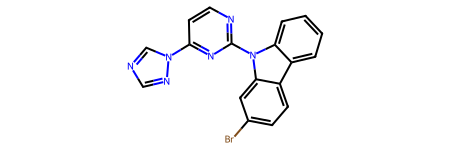

In [8]:
graphs, smiles_list = [], []
for row in rows:
    graph = smiles_to_graph(row["smiles"])
    if graph is None:
        raise ValueError("Invalid SMILES: " + row["smiles"])
    graphs.append(graph)
    smiles_list.append(row["smiles"])
labels = np.array([int(row["label"]) for row in rows])

sizes = [len(x) for _, x in graphs]
print(len(graphs), "molecules,", labels.sum(), "active,", len(labels) - labels.sum(), "inactive")
# this is the accuracy we would get by always predicting the majority class
print("majority baseline:", round(max(labels.mean(), 1 - labels.mean()), 3))
print("atoms per molecule: median", int(np.median(sizes)), " max", max(sizes))

a, x = graphs[4]
print("\nexample:", smiles_list[4])
print("  a is", a.shape, "-> bond codes")
print("  x is", x.shape, "-> one row per atom, 14 features each")
# this gets displayed automatically. RDKit Mol objects have a renderer, so this line draws an actual structural formula for the molecule
Chem.MolFromSmiles(smiles_list[4])   # Colab draws it

## 4. Zero padding into tensors

Because the molecules have different sizes, we would add 0 to make each molecule like the largest one (120).

In [9]:
max_atoms = max(sizes)
n_feats = graphs[0][1].shape[1]
# torch automatically fills the top left corner of each one and adds 0
x = torch.zeros(len(graphs), max_atoms, n_feats)
a = torch.zeros(len(graphs), max_atoms, max_atoms, dtype=torch.uint8)
y = torch.tensor(labels, dtype=torch.float)

for k, (adj, feats) in enumerate(graphs):
    n = len(feats)
    x[k, :n] = torch.tensor(feats, dtype=torch.float)
    a[k, :n, :n] = torch.tensor(adj)
print("x:", tuple(x.shape), " a:", tuple(a.shape))

x: (3839, 120, 14)  a: (3839, 120, 120)


## 5. Train/Validation/Test split

we follow this Bemis-Murcko scaffold so similar structure molecule are on the same side of the split, so there's no data leakage

In [10]:
# AI assisted with finding and implementing this specifc way of splitting the train/test
# instead of just doing a standard 70 20 10
groups = np.array([row["scaffold"] or "ACYCLIC" for row in rows])
splitter = StratifiedGroupKFold(n_splits=7, shuffle=True, random_state=seed)
folds = list(splitter.split(np.zeros(len(rows)), labels, groups))

splits = np.full(len(rows), "train", dtype="<U10")
splits[folds[0][1]] = "test"
splits[folds[1][1]] = "validation"
indices = {name: np.flatnonzero(splits == name) for name in ("train", "validation", "test")}
train_idx = indices["train"].copy()
val_idx = indices["validation"]

for name, idx in indices.items():
    print(name, len(idx), "molecules;", labels[idx].sum(), "active")

train 2576 molecules; 706 active
validation 832 molecules; 308 active
test 431 molecules; 120 active


## 6. SimpleGNN

orginally one layer is `relu(a @ lin(x))`：applies a linear transformation to every atom, taking it from 14 to 64. and then we ould mix with the neighbors

In [11]:
def message(x, a, norm, self_lin, bond_lins):
    # An atom keeps its own information and adds one message per bond type.
    # @ is matrix multiplication.
    total = (norm * (a == 5)) @ self_lin(x) #(a == 5 selects the diagnoal, which is themselves)
    for code, bond_lin in enumerate(bond_lins, start=1):
      # we loop through the four bond types, each with its own weight matrix
        total = total + (norm * (a == code)) @ bond_lin(x)
      # activation func
    return torch.relu(total)

In [12]:
class SimpleGNN(nn.Module):
    def __init__(self, n_feats, hidden=64):
        super().__init__()
        # this is the three layers from Jane's orginal model
        self.lin1 = nn.Linear(n_feats, hidden)
        self.lin2 = nn.Linear(hidden, hidden)
        self.out = nn.Linear(hidden, 1)
        # Each bond type starts as a copy, then learns its own transform.
        self.bond1 = nn.ModuleList([copy.deepcopy(self.lin1) for _ in range(4)])
        self.bond2 = nn.ModuleList([copy.deepcopy(self.lin2) for _ in range(4)])

    def forward(self, x, a):
        # Divide by the two atom degrees, counting every connection the same.
        connected = (a > 0).float()
        degree = connected.sum(-1).clamp(min=1).sqrt()
        # connected here discards the bond type and keeps only is there a link, so every bond is treated equally.
        norm = connected / degree[:, :, None] / degree[:, None, :]
        x = message(x, a, norm, self.lin1, self.bond1)
        x = message(x, a, norm, self.lin2, self.bond2)
        # the sum pooling, which is the end when we are doing the readout
        # the return value is a logit, and we would later apply sigmoid.
        return self.out(x.sum(1)).squeeze(-1)


## 7. Train and Eval



In [13]:
def predict(idx):
    # Score molecules in batches, without tracking gradients.
    model.eval()
    out = []
    # we disable this autograd, because we don't need it in inference
    with torch.no_grad():
        for i in range(0, len(idx), 128):
            b = idx[i:i + 128]
            # we map the logit to a score between 0 and 1
            out.append(torch.sigmoid(model(x[b], a[b])).numpy())
    return np.concatenate(out)

training setup

In [14]:
torch.manual_seed(seed)

model = SimpleGNN(n_feats)

# this is our parameters
# adam is our optimizer, learning rate, and l2 regularization here (to address overfit)
opt = torch.optim.Adam(model.parameters(), lr=1e-3, weight_decay=1e-4)

# this is to address class imbalance, because in this 2576 molecules only 706 are active.
# also, because we weighted the postiive class, that's why the decision threshold ends up at 0.688 rather than 0.5.
pos_weight = (1 - y[train_idx]).sum() / y[train_idx].sum()


# cross-entropy loss
loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

rng = np.random.default_rng(seed)
print("positive weight:", round(float(pos_weight), 3))

positive weight: 2.649


This is the standard PyTorch training step


1.   Clean the accumulated gradients
2.   run the forward pass and compute the loss
3.   run backpropagation
4.   take an optimizer step to update the weights





In [15]:
best_ap, best_epoch, stale = -1.0, 0, 0

for epoch in range(1, epochs + 1):
    model.train()
    # reshuffles each epoch so the batches differ
    rng.shuffle(train_idx)
    total_loss = 0.0
    for i in range(0, len(train_idx), 64):
        b = train_idx[i:i + 64]
        # step 1
        opt.zero_grad()
        # step 2
        loss = loss_fn(model(x[b], a[b]), y[b])
        # step 3
        loss.backward()
        # step 4
        opt.step()
        total_loss += loss.item() * len(b)

# we select the best model (or combination of weights) on average precision instead of accuracy
# because we care about the performance on the minority class as well.
    ap = float(average_precision_score(labels[val_idx], predict(val_idx)))
    if ap > best_ap + 1e-5:
        best_ap, best_epoch, stale = ap, epoch, 0
        # we save a checkpoint
        best_weights = copy.deepcopy(model.state_dict())
    else:
        stale += 1
    if epoch == 1 or epoch % 10 == 0:
        print("epoch", epoch, "loss", round(total_loss / len(train_idx), 4),
              "validation AP", round(ap, 4))
        # this is for early stopping
    if stale >= patience:
        break

print("Best epoch:", best_epoch, "with validation AP", round(best_ap, 4))

epoch 1 loss 1.0545 validation AP 0.3638
epoch 10 loss 0.9535 validation AP 0.4562
epoch 20 loss 0.8589 validation AP 0.4805
epoch 30 loss 0.8068 validation AP 0.4737
epoch 40 loss 0.766 validation AP 0.4884
epoch 50 loss 0.7291 validation AP 0.5526
epoch 60 loss 0.6956 validation AP 0.5048
epoch 70 loss 0.6712 validation AP 0.5691
epoch 80 loss 0.6566 validation AP 0.5753
epoch 90 loss 0.628 validation AP 0.587
epoch 100 loss 0.6053 validation AP 0.6036
epoch 110 loss 0.5969 validation AP 0.5976
epoch 120 loss 0.581 validation AP 0.6072
epoch 130 loss 0.5642 validation AP 0.5926
epoch 140 loss 0.5513 validation AP 0.6114
epoch 150 loss 0.5437 validation AP 0.6144
Best epoch: 133 with validation AP 0.634


## 8. Final Evaluation

In [16]:
# we restore the best checkpoint
# because when the loop ends, the model is at around epoch 150, but we want epoch 133 back.
model.load_state_dict(best_weights)
# we score all of the 3839 molecules
all_scores = predict(np.arange(len(y)))
print("scored", len(all_scores), "molecules")

scored 3839 molecules


choose the deciison threshold:
we need a cutoff to turn a continous score into a yes or no answer

In [17]:
# AI assisted with implementing the derivation of this threshold
# because we weighted the two labels differently so it's not 0.5

#roc curve returns the true positive rate and false positive rate at every candidate cutoff.
fpr, tpr, thresholds = roc_curve(labels[val_idx], all_scores[val_idx])
# tpr - fpr is Youden’s J statistic
youden = tpr - fpr                       # largest where balanced accuracy is largest
tied = thresholds[np.isclose(youden, youden.max())]
# roc_curve puts inf first; its youden is 0, so it never wins.
threshold = float(min(tied, key=lambda t: abs(t - 0.5)))
print("validation-selected threshold:", round(threshold, 4))

validation-selected threshold: 0.7047


**Compute the metrics**:


We compute accuracy, precision, recall, F1 score

We also compute ROC - AUC. These are independent from the threshold.

In [21]:
results = {}
for name, idx in indices.items():
    truth, scores = labels[idx], all_scores[idx]
    predicted = scores >= threshold
    r = {
        "accuracy": float(accuracy_score(truth, predicted)),
        "precision": float(precision_score(truth, predicted, zero_division=0)),
        "recall": float(recall_score(truth, predicted, zero_division=0)),
        "f1": float(f1_score(truth, predicted, zero_division=0)),
        "roc_auc": float(roc_auc_score(truth, scores)),
        "confusion_matrix": confusion_matrix(truth, predicted, labels=[0, 1]).tolist(),
    }
    results[name] = r
    print(name.upper(), " n =", len(indices[name]))
    print("  accuracy", round(r["accuracy"], 3), " precision", round(r["precision"], 3),
          " recall", round(r["recall"], 3), " F1", round(r["f1"], 3))
    print("  ROC-AUC", round(r["roc_auc"], 3), )
    print("  confusion [[TN, FP], [FN, TP]]:", r["confusion_matrix"])

TRAIN  n = 2576
  accuracy 0.856  precision 0.725  recall 0.766  F1 0.745
  ROC-AUC 0.912
  confusion [[TN, FP], [FN, TP]]: [[1665, 205], [165, 541]]
VALIDATION  n = 832
  accuracy 0.715  precision 0.611  recall 0.633  F1 0.622
  ROC-AUC 0.762
  confusion [[TN, FP], [FN, TP]]: [[400, 124], [113, 195]]
TEST  n = 431
  accuracy 0.768  precision 0.582  recall 0.592  F1 0.587
  ROC-AUC 0.683
  confusion [[TN, FP], [FN, TP]]: [[260, 51], [49, 71]]


## 9. Export the model

We download `model.npz`

In [ ]:
pairs = [(model.lin1, model.bond1), (model.lin2, model.bond2)]

weights = {"wout": model.out.weight, "bout": model.out.bias}

for i, (lin, bonds) in enumerate(pairs, start=1):
    weights["w" + str(i)], weights["b" + str(i)] = lin.weight, lin.bias
    weights["wb" + str(i)] = torch.stack([b.weight for b in bonds])
    weights["bb" + str(i)] = torch.stack([b.bias for b in bonds])

arrays = {name: value.detach().numpy() for name, value in weights.items()}
# this is what the visualization reads to know which model it is looking at
metadata = {
    "target": "CHEMBL354", "organism": "Escherichia coli", "endpoint": "MIC",
    "activity_rule": "MIC < 10000 nM; equality is inactive",
    "architecture": "Two bond-type GNN layers, sum pooling, linear output",
    "readout": "sum", "use_bonds": True, "message_layers": 2,
    "feature_names": feature_names, "bond_names": bond_names, "hidden": 64,
    "split_kind": "scaffold", "seed": seed, "best_epoch": best_epoch,
    "test_metrics": results["test"],
    "score_warning": "Weighted-loss sigmoid scores are not calibrated probabilities",
}

# we save the weights and the whole dataset in one file, so the viewer never recomputes anything
np.savez_compressed("model.npz", **arrays,
    smiles=np.array(smiles_list), labels=labels, names=np.array([r["name"] for r in rows]),
    splits=splits, reference_probabilities=all_scores,
    decision_threshold=np.array(threshold), metadata=np.array(json.dumps(metadata)))
# this downloads it to the laptop, and it becomes models/model.npz in the repo
files.download("model.npz")